# Results Plots

In [22]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import camb

import xqml

pars = camb.CAMBparams()

In [10]:
data = np.load("results/f60_noise90only2.npz")

noises = data["noises"]
sigma = data["sigma"]
bias = data["bias"]
ell_bins = data["ell_bins"]
cl_mean = data["cl_mean"]
cl_std = data["cl_std"]

In [11]:
goal = pd.read_csv("goal_table.csv", names=['noise','sigma_tau'])

goal_low = goal[goal['noise'] <= 100]

Text(0.5, 0.98, '400 simulations, fsky = 60%, noise only in 90 GHz channel')

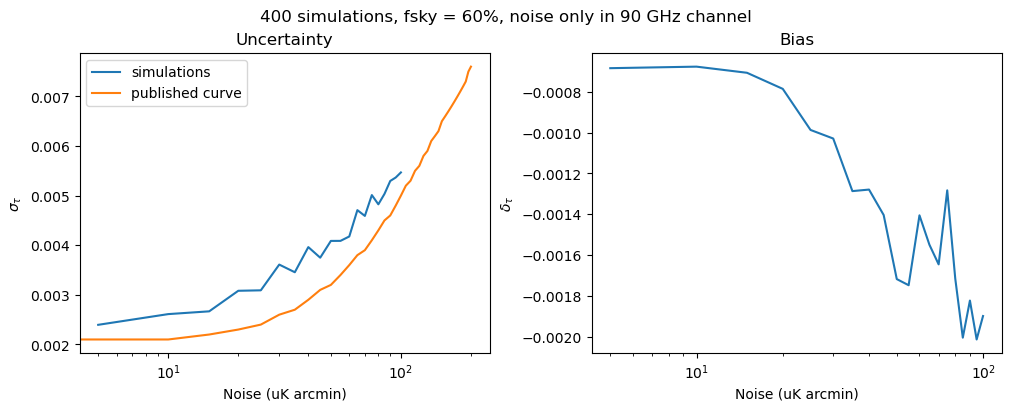

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(10,4), constrained_layout=True)
ax[0].semilogx(noises[1:], sigma[1:], label='simulations')
ax[0].semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
ax[0].set_ylabel(r'$\sigma_{\tau}$')
ax[0].set_xlabel("Noise (uK arcmin)")
ax[0].set_title("Uncertainty")
ax[0].legend()
ax[1].semilogx(noises[1:], bias[1:], label='simulations')
ax[1].set_ylabel(r'$\delta_{\tau}$')
ax[1].set_xlabel("Noise (uK arcmin)")
ax[1].set_title("Bias")
fig.suptitle("400 simulations, fsky = 60%, noise only in 90 GHz channel")

In [20]:
lmax_sim = 32
nside_sim = 128
lmax_xqml = 32
nside_xqml = 16

ls_sim = np.arange(2, lmax_sim+1)
ls_xqml = np.arange(2, lmax_xqml+1)

In [21]:
def get_Clhat(tau, lmax, raw_cl=True,
              H0=67, Ombh2=0.024, Omch2=0.12,
              As=2.1e-9, ns=0.965, ks=0.05, 
              kt=0.05, Omk=0, TCMB=2.7255, 
              mnu=0.06, r=0, YHe=0.245400,):
    '''
    Specify tau, and use other known parameters
    '''
    pars.set_cosmology(H0=H0, ombh2=Ombh2, omch2=Omch2, mnu=mnu, omk=Omk, tau=tau, TCMB=TCMB, YHe=YHe)
    pars.InitPower.set_params(As=As, ns=ns, r=r, pivot_scalar=ks, pivot_tensor=kt)
    results = camb.get_results(pars)
    powers = results.get_total_cls(lmax=lmax, CMB_unit='muK', raw_cl=True)
    TT, EE, BB, TE = powers.T
    #ls = np.arange(2, EE.shape[0]) # could add??
    return np.array([TT, EE, BB, TE])

true_tau = 0.054
true_spectra_sim = get_Clhat(true_tau, lmax=lmax_sim) # ensemble average power spectrum for higher resolution maps
true_spectra_xqml = get_Clhat(true_tau, lmax=lmax_xqml) # ensemble average power spectrum for xqml

In [23]:
DELL = 3
lmins = np.arange(2, lmax_xqml + 1 - DELL + 1, DELL)[:(lmax_xqml - 1) // DELL]
lmaxs = lmins + DELL
lmaxs[-1] = lmax_xqml + 1  # fromdeltal drops leftover ells, unmodelled power leaks into all bins
bins = xqml.Bins(lmins, lmaxs)
ell_bins = bins.lbin

In [25]:
print(len(cl_mean))

21


Text(0, 0.5, '$\\ell(\\ell+1)C_\\ell^{EE}/2\\pi$')

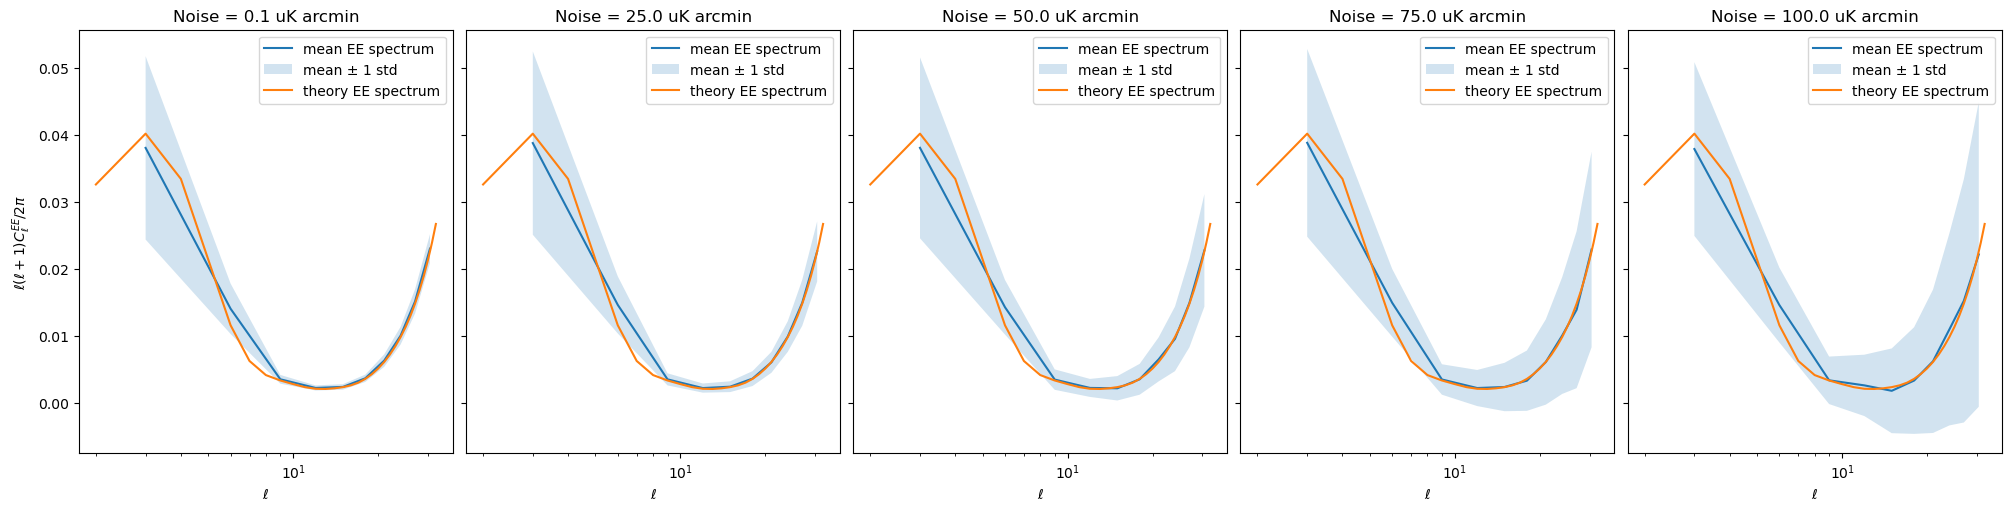

In [32]:
fig, ax = plt.subplots(1,5, figsize=(20,5), sharey=True,constrained_layout=True)
n = 0
Z_bin = ell_bins*(ell_bins+1)/(2*np.pi)
Z = ls_sim*(ls_sim+1)/(2*np.pi)
for i in (0,5,10,15,20):
    ax[n].semilogx(ell_bins, cl_mean[i]*Z_bin, label='mean EE spectrum')
    ax[n].fill_between(ell_bins, (cl_mean[i] - cl_std[i])*Z_bin, (cl_mean[i] + cl_std[i])*Z_bin, alpha=0.2, label='mean ± 1 std')
    ax[n].semilogx(ls_sim, true_spectra_sim[1][ls_sim]*Z, label='theory EE spectrum')
    ax[n].legend()
    ax[n].set_xlabel(r'$\ell$')
    ax[n].set_title(f"Noise = {noises[i]:.1f} uK arcmin")
    n += 1
ax[0].set_ylabel(r'$\ell(\ell+1)C_\ell^{EE}/2\pi$')